# KNN: standalone rolling tuning

This notebook evaluates only the **prediction layer** of the two-stage KNN; it does not call factor combination, clustering, selection or MVO.

The correct order is:

1. Compare KNN parameters over the Development period;
2. Keep only a few candidates and re-check them over the Validation period;
3. After freezing the KNN parameters, tune factor weights, selection and MVO in the full strategy;
4. Run Holdout only once, after all parameters are frozen.

Evaluation rolls strictly forward in time: the KNN at each `as_of` may only use data up to and including that day, and the actual 39-day future returns are used only for scoring after the fact. The main metric is the per-period cross-sectional Spearman Rank Information Coefficient (IC), while also checking MAE, direction accuracy, coverage, neighbor counts and warnings. Do not repeatedly pick KNN parameters based on a single cumulative return.


In [3]:
%load_ext autoreload
%autoreload 2

from dataclasses import asdict
from itertools import product
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pf.config
import pf.knn
import pf.loader


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Load data and lock the task setup

`holding_days` and the market data setup belong to the task definition and are not changed in KNN tuning. `fundamentals` is not used by the current KNN prediction, so revenue data is not loaded here.


In [4]:
cfg = pf.config.Config()
H = cfg.task.holding_days

prices = pf.loader.load_prices(cfg.data.price_file, cfg.data.price_col)
benchmarks = pf.loader.load_benchmarks(cfg.data.benchmark_file)
future_return = prices.shift(-H).div(prices).sub(1)

print(f"prices: {prices.index[0].date()} → {prices.index[-1].date()}, "
      f"{prices.shape[1]} tickers, horizon={H}")
display(pd.Series(asdict(cfg.factors.ret), name="KNN baseline params", dtype=object).to_frame())


prices: 2011-01-03 → 2026-09-25, 28 tickers, horizon=39


,KNN baseline params
market,^GSPC
market_pool_size,40
n_neighbors,15
min_neighbors,8
neighbor_gap,None
market_momentum_window,63
market_vol_window,21
market_drawdown_window,126
breadth_window,63
dispersion_window,21


## 2. Time split and staggered start dates

The defaults below use:

- 2011–2014: only as historical states and the neighbor library;
- 2015–2022: Development;
- 2023–2024: Validation;
- 2025 onward: Holdout; do not run before parameters are frozen.

Each evaluation subsequence still uses `step=H`, so adjacent labels within the same offset do not overlap. `EVAL_OFFSETS=(0, 10, 20, 30)` means starting at the 0th, 10th, 20th and 30th trading day after the period start, then evaluating every `H` days. The future return windows of different offsets may overlap, so these observations cannot be treated as fully independent samples; below, the mean IC of each offset is summarized separately and the worst offset is checked.

Random dates are not recommended as the main tuning sample: random results depend on the seed, may oversample certain market regimes, and easily produce overlapping labels. Random sampling is only suitable as a supplementary robustness check after parameters are frozen, with a fixed seed and stratified by year. Fixed staggered start dates are more even, reproducible and easier to audit.

`QUICK_RUN=True` samples only a few dates within each offset to check the code; change it to `False` when formally comparing parameters.

In [5]:
# SPLITS = {
#     "development": ("2015-01-01", "2018-12-31"),
#     "validation": ("2019-01-01", "2022-12-31"),
# }
# PHASE = "development"  # change to "validation" only after finishing the Development screening
# STEP = H
# EVAL_OFFSETS = (0, 10, 20, 30)
# QUICK_RUN = True
# QUICK_DATES_PER_OFFSET = 3
#
# def evaluation_dates(index, start, end, step, horizon, offset=0):
#     start = pd.Timestamp(start)
#     end = pd.Timestamp(end)
#     first = int(index.searchsorted(start, side="left")) + int(offset)
#     last = int(index.searchsorted(end, side="right")) - 1
#     max_as_of = last - horizon
#     if first > max_as_of:
#         raise ValueError(f"no complete prediction holding period in the range: offset={offset}")
#     return pd.DatetimeIndex(index[first : max_as_of + 1 : step], name="as_of")
#
# def build_evaluation_schedule(index, start, end, step, horizon, offsets, quick, quick_dates):
#     frames = []
#     for offset in offsets:
#         dates = evaluation_dates(index, start, end, step, horizon, offset)
#         if quick and len(dates) > quick_dates:
#             positions = np.linspace(0, len(dates) - 1, quick_dates).round().astype(int)
#             dates = dates[np.unique(positions)]
#         frames.append(pd.DataFrame({"as_of": dates, "offset": int(offset)}))
#     return pd.concat(frames, ignore_index=True).sort_values(["as_of", "offset"]).reset_index(drop=True)
#
# start, end = SPLITS[PHASE]
# eval_schedule = build_evaluation_schedule(
#     prices.index, start, end, STEP, H, EVAL_OFFSETS, QUICK_RUN, QUICK_DATES_PER_OFFSET
# )
#
# print(
#     f"phase={PHASE}, observations={len(eval_schedule)}, "
#     f"{eval_schedule['as_of'].min().date()} → {eval_schedule['as_of'].max().date()}, "
#     f"offsets={EVAL_OFFSETS}, quick={QUICK_RUN}"
# )
# display(eval_schedule.groupby("offset")["as_of"].agg(["count", "min", "max"]))

phase=development, observations=12, 2015-01-02 → 2018-11-01, offsets=(0, 10, 20, 30), quick=True


,count,min,max
offset,,,
0,3,2015-01-02,2018-09-20
10,3,2015-01-16,2018-10-04
20,3,2015-02-02,2018-10-18
30,3,2015-02-17,2018-11-01


## 3. Parameter candidates: KNN structure and time windows

The candidates come in parts:

1. `PARAM_GRID` adjusts the candidate pool size and number of neighbors;
2. `DISTANCE_WEIGHT_PAIRS` explicitly lists the weight pairs for the market/stock distance blocks;
3. `WINDOW_PROFILES` adjusts the market and stock momentum, volatility, drawdown, breadth and dispersion windows.

The stock distance actually includes momentum relative to the market, market-regression residual momentum, annualized idiosyncratic volatility and raw stock drawdown. `stock_momentum_window` controls the observation period of both momentum measures; `stock_vol_window` controls the estimation period of both the rolling alpha/beta and the idiosyncratic volatility.

Three window profiles are provided by default: short, baseline and long. Profiles are used instead of a full Cartesian product over all eight windows to control computation and the risk of multiple testing; if each window had three values, the windows alone would produce `3^8=6561` combinations. First compare the three overall scales, then fine-tune one or two windows at a time around a configuration that performs stably.

The default quick run has 3 window profiles × 8 structure/weight combinations × 4 offsets × 3 dates per offset, 288 KNN calls in total. Before a formal run, check the call count printed below. `(1, 0)` means stage two keeps only the market distance, `(0, 1)` means stage two keeps only the stock distance; in the latter case the stage-one candidate pool is still filtered by market distance, so it is not fully detached from the market state.

In [6]:
BASE_PARAMS = asdict(cfg.factors.ret)

WINDOW_KEYS = (
    "market_momentum_window",
    "market_vol_window",
    "market_drawdown_window",
    "breadth_window",
    "dispersion_window",
    "stock_momentum_window",
    "stock_vol_window",
    "stock_drawdown_window",
)

WINDOW_PROFILES = {
    "short": {
        "market_momentum_window": 21,
        "market_vol_window": 21,
        "market_drawdown_window": 63,
        "breadth_window": 21,
        "dispersion_window": 21,
        "stock_momentum_window": 21,
        "stock_vol_window": 21,
        "stock_drawdown_window": 63,
    },
    "baseline": {key: BASE_PARAMS[key] for key in WINDOW_KEYS},
    "long": {
        "market_momentum_window": 126,
        "market_vol_window": 63,
        "market_drawdown_window": 252,
        "breadth_window": 126,
        "dispersion_window": 63,
        "stock_momentum_window": 126,
        "stock_vol_window": 126,
        "stock_drawdown_window": 252,
    },
}

PARAM_GRID = {
    "market_pool_size": [40],
    "n_neighbors": [10, 15],
}

DISTANCE_WEIGHT_PAIRS = (
    (1.0, 0.0),  # stage two uses only the market distance
    (0.0, 1.0),  # stage two uses only the stock distance; stage one still filters the candidate pool by market
    (1.0, 1.0),  # equal weights for both distance blocks
    (1.0, 2.0),  # stock distance block weighted up
)

def parameter_candidates(base, grid, window_profiles, weight_pairs):
    keys = list(grid)
    candidates = []
    if len(set(weight_pairs)) != len(weight_pairs):
        raise ValueError("DISTANCE_WEIGHT_PAIRS must not contain duplicate weight pairs")
    for market_weight, stock_weight in weight_pairs:
        if market_weight < 0 or stock_weight < 0 or market_weight + stock_weight <= 0:
            raise ValueError(f"invalid distance weight pair: {(market_weight, stock_weight)}")
    for profile_name, windows in window_profiles.items():
        missing = set(WINDOW_KEYS).difference(windows)
        extra = set(windows).difference(WINDOW_KEYS)
        if missing or extra:
            raise ValueError(
                f"window profile {profile_name!r} has wrong fields: missing={sorted(missing)}, extra={sorted(extra)}"
            )
        for values in product(*(grid[key] for key in keys)):
            base_structural = dict(zip(keys, values))
            for market_weight, stock_weight in weight_pairs:
                structural = {
                    **base_structural,
                    "market_distance_weight": market_weight,
                    "stock_distance_weight": stock_weight,
                }
                params_dict = {**base, **windows, **structural}
                if params_dict["market_pool_size"] < params_dict["n_neighbors"]:
                    continue
                description = {"window_profile": profile_name, **structural, **windows}
                candidates.append((description, pf.config.KNNParams(**params_dict)))
    return candidates

candidates = parameter_candidates(
    BASE_PARAMS, PARAM_GRID, WINDOW_PROFILES, DISTANCE_WEIGHT_PAIRS
)
print(f"parameter sets: {len(candidates)}; KNN runs: {len(candidates) * len(eval_schedule)}")
display(pd.DataFrame([description for description, _ in candidates]))

parameter sets: 24; KNN runs: 288


,window_profile,market_pool_size,n_neighbors,market_distance_weight,stock_distance_weight,market_momentum_window,market_vol_window,market_drawdown_window,breadth_window,dispersion_window,stock_momentum_window,stock_vol_window,stock_drawdown_window
0,short,40,10,1.0,0.0,21,21,63,21,21,21,21,63
1,short,40,10,0.0,1.0,21,21,63,21,21,21,21,63
2,short,40,10,1.0,1.0,21,21,63,21,21,21,21,63
3,short,40,10,1.0,2.0,21,21,63,21,21,21,21,63
4,short,40,15,1.0,0.0,21,21,63,21,21,21,21,63
5,short,40,15,0.0,1.0,21,21,63,21,21,21,21,63
6,short,40,15,1.0,1.0,21,21,63,21,21,21,21,63
7,short,40,15,1.0,2.0,21,21,63,21,21,21,21,63
8,baseline,40,10,1.0,0.0,63,21,126,63,21,63,63,126
9,baseline,40,10,0.0,1.0,63,21,126,63,21,63,63,126


## 4. Evaluation metrics and parameter selection rules

On each `as_of` date, KNN predicts the returns of all available stocks over the next `H` trading days. This notebook first computes cross-sectional metrics per day, then aggregates across dates and offsets. **Tuning uses only Development; Validation confirms whether the conclusions are stable; Holdout is evaluated only once after all parameters are frozen.**

### Metric definitions

| Metric | Meaning | Direction | Use |
| --- | --- | --- | --- |
| `mean_ic` | Mean Spearman Rank IC over all evaluation dates. The daily IC is the correlation between the "predicted return ranking" and the "actual future return ranking" | Higher is better | **Main ranking metric**, judging cross-sectional stock selection ability |
| `median_ic` | Median IC over all evaluation dates | Higher is better | Checks whether `mean_ic` is inflated by a few extreme dates |
| `ic_std` | Standard deviation of IC across evaluation dates | Lower is more stable | Measures time variation of predictive power; different offsets have overlapping labels, so it should not be used directly for significance tests as if samples were independent |
| `ic_ir` | `mean_ic / ic_std`, not annualized in this notebook | Higher is better | Compares overall stability when mean ICs are close |
| `positive_ic_rate` | Share of evaluation dates with IC above 0 | Higher is better | Judges whether positive predictive power is persistent |
| `worst_offset_mean_ic` | Minimum of the mean ICs of the fixed offsets | Higher is better | **Start-date robustness metric**; avoids results that hold only for one start date |
| `offset_ic_std` | Standard deviation of the mean ICs across offsets | Lower is better | Measures sensitivity of results to the start date |
| `positive_offset_rate` | Share of offsets with mean IC above 0 | Higher is better | Checks whether the direction is consistent across staggered subsequences |
| `mean_mae` | Cross-date mean of the absolute error between predicted and actual returns | Lower is better | Checks the numerical scale of predicted returns; MVO later uses the predicted values directly, so ranking alone is not enough |
| `mean_rmse` | Cross-date mean of the root mean squared error, more sensitive to extreme errors | Lower is better | Helps identify a few severely wrong predictions |
| `direction_accuracy` | Share of predictions whose up/down direction matches the actual | Higher is better | Auxiliary metric; can be inflated when the market broadly rises or falls, so do not use it alone |
| `coverage` | Number of valid predictions ÷ number of stocks evaluable that day | Higher is better | **Hard usability check**; parameters with insufficient coverage should not enter the ranking |
| `median_neighbors` | Median number of neighbors actually used for prediction | Closer to the target `n_neighbors` is better | Checks whether short listing histories etc. lead to too few neighbors |
| `thin_neighbor_rate` | Share of evaluable stocks with more than 0 but fewer than `min_neighbors` neighbors | Lower is better | Measures how often low-sample predictions occur |
| `warning_dates` | Number of evaluation dates producing at least one KNN `UserWarning` | Lower is better | Locates data availability issues such as too few neighbors; interpret together with the warning content |

IC is defined as:

```text
IC(as_of) = corr(rank(predicted H-day return), rank(actual H-day return))
```

`IC = 1` means the rankings agree perfectly, `IC = 0` means no clear ranking information, and `IC < 0` means the predicted ranking is reversed overall. IC measures **relative strength ranking**, not whether the predicted return values are accurate.

### Recommended parameter selection order

1. First exclude configurations that failed to run, have clearly insufficient `coverage` (95% can serve as an initial reference line), or have too high `thin_neighbor_rate` or `warning_dates`.
2. Mainly compare `mean_ic` and `median_ic`, while requiring `worst_offset_mean_ic` not to be clearly negative and `positive_offset_rate` to be high.
3. When mean ICs are close, choose the configuration with lower `offset_ic_std` and `ic_std` and higher `ic_ir`.
4. Then compare `mean_mae` and `mean_rmse`. KNN output also feeds into MVO; when the scale of predicted values is badly distorted, unreasonable weights can result even if IC is good.
5. Development only produces a few candidates; candidates must keep the same direction and similar performance on Validation. Do not keep changing parameters based on Holdout results.

Do not treat the top result of the default quick run as the final parameters: `QUICK_RUN=True` only checks the pipeline; formal comparison requires `QUICK_RUN=False`.

## 5. Rolling evaluation function for one parameter set

For each date, first generate predictions, then compare with the actual return through the `H`-th trading day after that date. Dates are aggregated with equal weight, so dates with more available stocks do not naturally get more weight.


In [7]:
def rank_ic(predicted, actual):
    valid = predicted.notna() & actual.notna()
    if valid.sum() < 2:
        return np.nan
    return predicted[valid].rank(method="average").corr(actual[valid].rank(method="average"))

def evaluate_knn(params, schedule, config_id):
    date_rows = []
    prediction_rows = []
    started = time.perf_counter()

    for row in schedule.itertuples(index=False):
        as_of = row.as_of
        offset = int(row.offset)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", UserWarning)
            result = pf.knn.predict_return_details(
                prices, None, benchmarks, as_of, H, params
            )

        predicted = result.predicted_return
        actual = future_return.loc[as_of]
        evaluable = actual.notna()
        valid = predicted.notna() & evaluable
        error = predicted[valid] - actual[valid]
        counts = result.neighbor_count[evaluable]

        date_rows.append({
            "config_id": config_id,
            "as_of": as_of,
            "offset": offset,
            "ic": rank_ic(predicted, actual),
            "mae": error.abs().mean(),
            "rmse": np.sqrt(error.pow(2).mean()),
            "direction_accuracy": (np.sign(predicted[valid]) == np.sign(actual[valid])).mean(),
            "coverage": valid.sum() / max(int(evaluable.sum()), 1),
            "median_neighbors": counts[counts > 0].median(),
            "thin_neighbor_rate": ((counts > 0) & (counts < params.min_neighbors)).mean(),
            "warning_count": sum(issubclass(w.category, UserWarning) for w in caught),
            "valid_predictions": int(valid.sum()),
        })

        frame = pd.DataFrame({
            "predicted": predicted,
            "actual": actual,
            "uncertainty": result.uncertainty,
            "neighbor_count": result.neighbor_count,
        }).loc[valid].reset_index(names="ticker")
        frame.insert(0, "offset", offset)
        frame.insert(0, "as_of", as_of)
        frame.insert(0, "config_id", config_id)
        prediction_rows.append(frame)

    by_date = pd.DataFrame(date_rows).set_index("as_of").sort_index()
    predictions = pd.concat(prediction_rows, ignore_index=True)
    elapsed = time.perf_counter() - started
    ic_std = by_date["ic"].std(ddof=1)
    offset_mean_ic = by_date.groupby("offset")["ic"].mean()
    offset_ic_std = offset_mean_ic.std(ddof=1)
    summary = {
        "config_id": config_id,
        "mean_ic": by_date["ic"].mean(),
        "median_ic": by_date["ic"].median(),
        "ic_std": ic_std,
        "ic_ir": by_date["ic"].mean() / ic_std if pd.notna(ic_std) and ic_std > 0 else np.nan,
        "positive_ic_rate": by_date["ic"].gt(0).mean(),
        "worst_offset_mean_ic": offset_mean_ic.min(),
        "offset_ic_std": offset_ic_std,
        "positive_offset_rate": offset_mean_ic.gt(0).mean(),
        "mean_mae": by_date["mae"].mean(),
        "mean_rmse": by_date["rmse"].mean(),
        "direction_accuracy": by_date["direction_accuracy"].mean(),
        "coverage": by_date["coverage"].mean(),
        "median_neighbors": by_date["median_neighbors"].median(),
        "thin_neighbor_rate": by_date["thin_neighbor_rate"].mean(),
        "warning_dates": by_date["warning_count"].gt(0).sum(),
        "dates": len(by_date),
        "offsets": offset_mean_ic.size,
        "elapsed_seconds": elapsed,
    }
    return summary, by_date, predictions

## 6. Run the grid

First keep `QUICK_RUN=True` to confirm the full pipeline, then turn off quick mode. A formal run includes several window profiles and staggered start dates and may take several minutes; check the KNN call count printed above before running. When a parameter set fails, the error is recorded without interrupting the other combinations.

Ranking is mainly by overall mean IC, using the worst offset and the variation across offsets to break close results. The top result here is only a Development candidate, not the final parameters.

In [8]:
summaries = []
params_by_id = {}
date_metrics_by_id = {}
predictions_by_id = {}

for i, (description, params) in enumerate(candidates, start=1):
    config_id = f"cfg_{i:03d}"
    params_by_id[config_id] = params
    print(
        f"[{i}/{len(candidates)}] {config_id}: "
        f"profile={description['window_profile']}, "
        f"neighbors={description['n_neighbors']}, "
        f"weights={description['market_distance_weight']}:{description['stock_distance_weight']}"
    )
    try:
        summary, by_date, predictions = evaluate_knn(params, eval_schedule, config_id)
        summary.update(description)
        summary["status"] = "ok"
        summaries.append(summary)
        date_metrics_by_id[config_id] = by_date
        predictions_by_id[config_id] = predictions
    except Exception as exc:
        summaries.append({
            "config_id": config_id,
            **description,
            "status": "error",
            "error": f"{type(exc).__name__}: {exc}",
        })

summary_table = pd.DataFrame(summaries).set_index("config_id")
ranking = summary_table.query("status == 'ok'").sort_values(
    ["mean_ic", "worst_offset_mean_ic", "offset_ic_std", "mean_mae"],
    ascending=[False, False, True, True],
)
display(ranking.round(4))

errors = summary_table.query("status == 'error'")
if not errors.empty:
    display(errors[["error"]])

[1/24] cfg_001: profile=short, neighbors=10, weights=1.0:0.0
[2/24] cfg_002: profile=short, neighbors=10, weights=0.0:1.0
[3/24] cfg_003: profile=short, neighbors=10, weights=1.0:1.0
[4/24] cfg_004: profile=short, neighbors=10, weights=1.0:2.0
[5/24] cfg_005: profile=short, neighbors=15, weights=1.0:0.0
[6/24] cfg_006: profile=short, neighbors=15, weights=0.0:1.0
[7/24] cfg_007: profile=short, neighbors=15, weights=1.0:1.0
[8/24] cfg_008: profile=short, neighbors=15, weights=1.0:2.0
[9/24] cfg_009: profile=baseline, neighbors=10, weights=1.0:0.0
[10/24] cfg_010: profile=baseline, neighbors=10, weights=0.0:1.0
[11/24] cfg_011: profile=baseline, neighbors=10, weights=1.0:1.0
[12/24] cfg_012: profile=baseline, neighbors=10, weights=1.0:2.0
[13/24] cfg_013: profile=baseline, neighbors=15, weights=1.0:0.0
[14/24] cfg_014: profile=baseline, neighbors=15, weights=0.0:1.0
[15/24] cfg_015: profile=baseline, neighbors=15, weights=1.0:1.0
[16/24] cfg_016: profile=baseline, neighbors=15, weights=1

,mean_ic,median_ic,ic_std,ic_ir,positive_ic_rate,worst_offset_mean_ic,offset_ic_std,positive_offset_rate,mean_mae,mean_rmse,...,stock_distance_weight,market_momentum_window,market_vol_window,market_drawdown_window,breadth_window,dispersion_window,stock_momentum_window,stock_vol_window,stock_drawdown_window,status
config_id,,,,,,,,,,,,,,,,,,,,,
cfg_015,0.0835,0.1042,0.1774,0.4707,0.6667,0.0700,0.0158,1.00,0.0851,0.1246,...,1.0,63,21,126,63,21,63,63,126,ok
cfg_011,0.0831,0.1338,0.1696,0.4903,0.8333,-0.0105,0.1020,0.75,0.0861,0.1275,...,1.0,63,21,126,63,21,63,63,126,ok
cfg_008,0.0798,0.0554,0.2280,0.3501,0.6667,-0.1046,0.1251,0.75,0.0842,0.1210,...,2.0,21,21,63,21,21,21,21,63,ok
cfg_016,0.0790,0.1119,0.2168,0.3646,0.5833,0.0408,0.0369,1.00,0.0847,0.1244,...,2.0,63,21,126,63,21,63,63,126,ok
cfg_001,0.0786,0.0212,0.2625,0.2994,0.5833,-0.1056,0.1449,0.75,0.0866,0.1251,...,0.0,21,21,63,21,21,21,21,63,ok
cfg_009,0.0785,0.1269,0.2156,0.3642,0.5833,0.0149,0.0479,1.00,0.0863,0.1255,...,0.0,63,21,126,63,21,63,63,126,ok
cfg_003,0.0723,0.1196,0.1774,0.4076,0.6667,0.0113,0.0655,1.00,0.0839,0.1222,...,1.0,21,21,63,21,21,21,21,63,ok
cfg_004,0.0441,0.0385,0.1362,0.3238,0.6667,-0.0187,0.0506,0.75,0.0864,0.1237,...,2.0,21,21,63,21,21,21,21,63,ok
cfg_013,0.0406,0.0781,0.2496,0.1626,0.6667,-0.0818,0.0821,0.75,0.0858,0.1262,...,0.0,63,21,126,63,21,63,63,126,ok


## 7. Start date, time and neighbor diagnostics

Ranking cannot rely on the overall mean IC alone. First compare the mean IC of each offset: if a parameter set performs well only for one start date, the result is sensitive to the choice of evaluation dates. Different offsets have overlapping labels, so the offset table is mainly for robustness comparison, not for enlarging the sample size for statistical significance.

Then look at the per-date scatter plot to judge whether negative ICs are concentrated in particular market regimes. Prefer regions where different offsets and dates point in the same direction, coverage is high, neighbor counts are reasonable, and nearby parameters give similar results.

,cfg_015,cfg_011,cfg_008
offset,,,
0,0.0838,-0.0105,-0.1046
10,0.0746,0.1592,0.1197
20,0.1056,0.1828,0.1310
30,0.0700,0.0010,0.1731


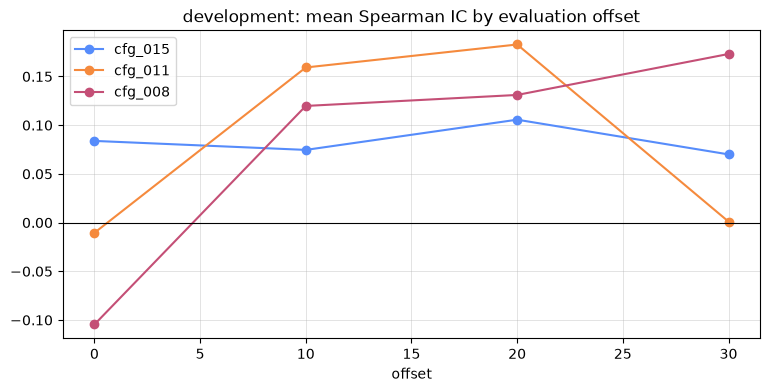

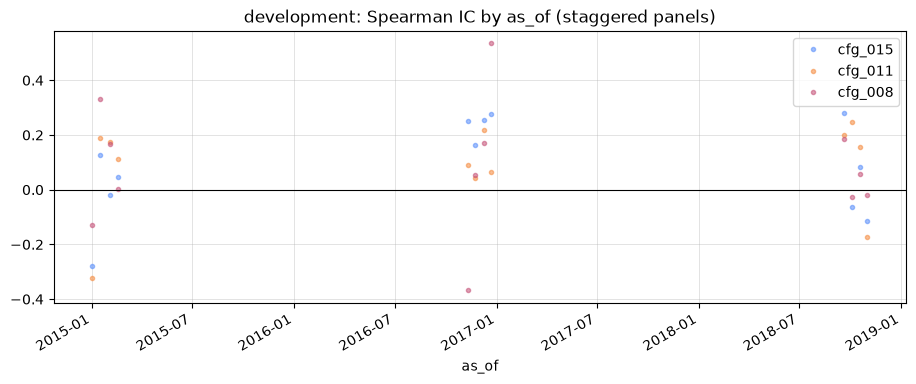

,mean,std,min,50%,max
cfg_015,0.0835,0.1774,-0.2792,0.1042,0.2800
cfg_011,0.0831,0.1696,-0.3223,0.1338,0.2462
cfg_008,0.0798,0.2280,-0.3685,0.0554,0.5354


In [9]:
TOP_N = min(3, len(ranking))
if TOP_N:
    top_ids = ranking.index[:TOP_N]
    offset_ic_frame = pd.DataFrame({
        config_id: date_metrics_by_id[config_id].groupby("offset")["ic"].mean()
        for config_id in top_ids
    })
    display(offset_ic_frame.round(4))
    ax = offset_ic_frame.plot(
        marker="o",
        figsize=(9, 4),
        grid=True,
        title=f"{PHASE}: mean Spearman IC by evaluation offset",
    )
    ax.axhline(0.0, color="black", linewidth=0.8)
    plt.show()

    ic_frame = pd.concat(
        {config_id: date_metrics_by_id[config_id]["ic"] for config_id in top_ids},
        axis=1,
    ).sort_index()
    ax = ic_frame.plot(
        style="o",
        markersize=3,
        alpha=0.55,
        figsize=(11, 4),
        grid=True,
        title=f"{PHASE}: Spearman IC by as_of (staggered panels)",
    )
    ax.axhline(0.0, color="black", linewidth=0.8)
    plt.show()
    display(ic_frame.describe().T[["mean", "std", "min", "50%", "max"]].round(4))

In [10]:
BEST_ID = ranking.index[0]  # the Development winner is only a Validation candidate, not the final conclusion
best_params = params_by_id[BEST_ID]
inspect_date = eval_schedule["as_of"].max()

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", UserWarning)
    detail = pf.knn.predict_return_details(
        prices, None, benchmarks, inspect_date, H, best_params
    )

diagnostic = pd.DataFrame({
    "predicted_return": detail.predicted_return,
    "actual_return": future_return.loc[inspect_date],
    "outcome_dispersion": detail.outcome_dispersion,
    "uncertainty": detail.uncertainty,
    "neighbor_count": detail.neighbor_count,
}).sort_values("predicted_return", ascending=False)

print(f"BEST_ID={BEST_ID}, inspect_date={inspect_date.date()}")
print("warnings:", [str(w.message) for w in caught])
display(diagnostic.round(4))

BEST_ID=cfg_015, inspect_date=2018-11-01
warnings: []


,predicted_return,actual_return,outcome_dispersion,uncertainty,neighbor_count
ticker,,,,,
MPC,0.0954,-0.1698,0.1415,0.0458,15
ABBV,0.0815,0.1494,0.1170,0.0379,15
GOOGL,0.0778,-0.0378,0.1113,0.0360,15
EOG,0.0774,-0.1841,0.1240,0.0401,15
LLY,0.0682,0.0729,0.0574,0.0186,15
GE,0.0632,-0.2098,0.0769,0.0249,15
AVGO,0.0512,0.1061,0.0656,0.0212,15
V,0.0395,-0.0631,0.0464,0.0150,15
MCD,0.0384,0.0154,0.0483,0.0156,15


## 8. Development → Validation → freeze

Do not write the Development winner straight into the final strategy. Recommended process:

1. Keep `QUICK_RUN=True` and confirm that all window profiles, offsets and metrics run correctly;
2. Change to `QUICK_RUN=False` and compare the short, baseline and long window profiles on Development;
3. Keep 2–3 candidates from Development that are stable across offsets;
4. If fine-tuning is needed, change only one or two windows at a time around the candidates; do not run a large Cartesian product over all windows;
5. Change `PHASE` to `"validation"` and re-check only a few candidates;
6. On Validation, check IC, worst offset, MAE, coverage and neighbor stability together;
7. Choose a simple configuration in a stable region, update the frozen values as the `config.KNNParams` defaults and commit;
8. From then on `run.ipynb` only reads the frozen parameters and no longer tunes KNN;
9. The Holdout after 2023 is run only once, after the full strategy's parameters are frozen.

If you want a random-date check, do it after the parameters are frozen in step 7, with a fixed random seed and stratified by year; it can only serve as sensitivity analysis, and parameters must not be picked further based on the random check.

Below generates the configuration text of the final candidate, for updating `config.py` after review; it does not modify any file automatically.

In [11]:
print("Frozen candidate parameters:")
for key, value in asdict(best_params).items():
    print(f"{key} = {value!r}")


Frozen candidate parameters:
market = '^GSPC'
market_pool_size = 40
n_neighbors = 15
min_neighbors = 8
neighbor_gap = None
market_momentum_window = 63
market_vol_window = 21
market_drawdown_window = 126
breadth_window = 63
dispersion_window = 21
stock_momentum_window = 63
stock_vol_window = 63
stock_drawdown_window = 126
market_distance_weight = 1.0
stock_distance_weight = 1.0
